# Muller's Ratchet and the Evolutionary Rescue by Recombination
### Does recombination quantifiably slow an asexual population's irreversible mutational decline?

Builds a real, finite-population genetic model of recurring deleterious mutation under purifying
selection. Confirms, by direct comparison against an exact infinite-population recursion, that irreversible
mutational decline (Muller's ratchet) requires genetic drift — it does not happen without finite population
size. Builds a separate recombining variant of the same model and directly, quantitatively measures how
much free recombination slows or halts the ratchet, then searches for a real parameter regime where that
rescue effect weakens.


## Step 0 — Environment setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import poisson

np.set_printoptions(precision=4, suppress=True)
print("numpy:", np.__version__)


numpy: 2.4.6


## Step 1 — Deterministic (infinite-population) class-frequency recursion

Individuals carry `k=0,1,2,...` deleterious mutations; fitness is multiplicative, `w_k = (1-s)^k`. Each
generation: selection (reweight by fitness), then mutation (each individual independently gains
`Poisson(U)` new mutations). In an INFINITE population this process has an exact closed-form equilibrium
(the Haigh/Kimura-Maruyama result): class frequencies converge to a `Poisson(U/s)` distribution over
mutation counts — confirmed below to match to floating-point precision.


In [2]:
U, s = 0.3, 0.1
kmax = 80

def deterministic_step(p, U, s):
    k = np.arange(len(p))
    w = (1-s)**k
    p_sel = p*w/(p*w).sum()  # p*w / (p*w).sum()
    mut_kernel = poisson.pmf(np.arange(kmax+1), U)
    p_new = np.convolve(p_sel, mut_kernel)[:len(p)]
    p_new = p_new/p_new.sum()  # p_new / p_new.sum()
    return p_new

p = np.zeros(kmax+1)
p[0] = 1.0
for gen in range(3000):
    p = deterministic_step(p, U, s)

theory = poisson.pmf(np.arange(10), U/s)  # poisson.pmf(np.arange(10), U/s)
print("Deterministic equilibrium, first 10 classes:")
print(p[:10])
print("Closed-form Poisson(U/s), first 10 classes:")
print(theory)
print("\nmax abs difference:", np.max(np.abs(p[:10]-theory)))
print("p0 (least-loaded class frequency):", p[0], "  exp(-U/s) =", np.exp(-U/s))


Deterministic equilibrium, first 10 classes:
[0.0498 0.1494 0.224  0.224  0.168  0.1008 0.0504 0.0216 0.0081 0.0027]
Closed-form Poisson(U/s), first 10 classes:
[0.0498 0.1494 0.224  0.224  0.168  0.1008 0.0504 0.0216 0.0081 0.0027]

max abs difference: 5.551115123125783e-17
p0 (least-loaded class frequency): 0.049787068367863944   exp(-U/s) = 0.049787068367863965


## Step 2 — Finite-population asexual Wright-Fisher simulation

A real population has a finite number of individuals `N`. Each generation, the next generation's `N`
individuals are a fitness-weighted random sample (with replacement) of the current generation — this is
where genuine drift, and therefore a real chance of losing the least-loaded class entirely, can happen.
Since offspring inherit their single parent's full mutation set unchanged, each individual only needs to be
represented by its mutation count (an integer), not the specific mutations it carries.


In [3]:
def wf_asexual_sim(N, U, s, n_gen, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    counts = np.zeros(N, dtype=int)
    click_gens = []
    current_min = 0
    min_trace = []
    for gen in range(n_gen):
        w = (1-s)**counts
        probs = w/w.sum()  # w / w.sum()
        parents = rng.choice(N, size=N, p=probs)  # rng.choice(N, size=N, p=probs)
        counts = counts[parents] + rng.poisson(U, size=N)  # counts[parents] + rng.poisson(U, size=N)
        min_trace.append(counts.min())
        if counts.min() > current_min:
            click_gens.append(gen)
            current_min = counts.min()  # counts.min()
    return click_gens, np.array(min_trace)

rng = np.random.default_rng(1)
example_clicks, example_trace = wf_asexual_sim(50, 0.3, 0.1, 2000, rng=rng)
print(f"Example (N=50, U=0.3, s=0.1): {len(example_clicks)} clicks over 2000 generations")
print(f"Final least-loaded class: {example_trace[-1]} mutations")


Example (N=50, U=0.3, s=0.1): 118 clicks over 2000 generations
Final least-loaded class: 119 mutations


## Step 3 — Parameter sensitivity sweep, asexual model

Before trusting any further result from this simulation, three real, checkable sensitivity directions are
confirmed: smaller `N` gives more clicks (stronger drift), higher `U` gives more clicks (more mutation
pressure), and higher `s` gives fewer clicks (stronger purifying selection counteracts drift more
effectively).


In [4]:
sweep_configs = [
    dict(N=50, U=0.3, s=0.1),
    dict(N=200, U=0.3, s=0.1),
    dict(N=50, U=0.1, s=0.1),
    dict(N=50, U=0.3, s=0.3),
]
n_gen_sweep = 2000
sweep_rows = []
for cfg in sweep_configs:
    rng = np.random.default_rng(42)
    clicks, trace = wf_asexual_sim(cfg["N"], cfg["U"], cfg["s"], n_gen_sweep, rng=rng)  # wf_asexual_sim(cfg["N"], cfg["U"], cfg["s"], n_gen_sweep, rng=rng)
    sweep_rows.append({**cfg, "n_clicks": len(clicks), "final_min_class": trace[-1]})  # {**cfg, "n_clicks": len(clicks), "final_min_class": trace[-1]}

sweep_df = pd.DataFrame(sweep_rows)
print(sweep_df)
print()
print("Smaller N -> more clicks:", sweep_df.loc[0,'n_clicks'] > sweep_df.loc[1,'n_clicks'])
print("Smaller U -> fewer clicks:", sweep_df.loc[2,'n_clicks'] < sweep_df.loc[0,'n_clicks'])
print("Larger s -> fewer clicks:", sweep_df.loc[3,'n_clicks'] < sweep_df.loc[0,'n_clicks'])


     N    U    s  n_clicks  final_min_class
0   50  0.3  0.1       124              124
1  200  0.3  0.1        44               44
2   50  0.1  0.1        24               24
3   50  0.3  0.3         1                1

Smaller N -> more clicks: True
Smaller U -> fewer clicks: True
Larger s -> fewer clicks: True


## Step 4 — Recombining Wright-Fisher simulation

Recombination lets an offspring inherit a new combination of its two parents' mutations, not just one
parent's full set. For each mutation present in BOTH parents, the offspring always inherits it. For each
mutation present in only ONE parent, the offspring inherits it independently with probability 1/2 (free,
unlinked recombination). This means an offspring can end up with fewer mutations than either parent, if the
parents' private mutations happen not to be passed on — the real rescue mechanism. Each individual is
represented as a Python `set` of mutation IDs (not a count) since recombination needs to know WHICH
mutations are shared vs. private.


In [5]:
def wf_sexual_sim(N, U, s, n_gen, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    genotypes = [set() for _ in range(N)]
    next_mut_id = 0
    click_gens = []
    current_min = 0
    min_trace = []
    for gen in range(n_gen):
        counts = np.array([len(g) for g in genotypes])
        w = (1-s)**counts
        probs = w / w.sum()
        p1_idx = rng.choice(N, size=N, p=probs)
        p2_idx = rng.choice(N, size=N, p=probs)  # rng.choice(N, size=N, p=probs)
        new_genotypes = []
        for i in range(N):
            gA, gB = genotypes[p1_idx[i]], genotypes[p2_idx[i]]
            shared = gA & gB  # gA & gB
            private = (gA| gB)  # (gA | gB) - shared
            inherited_private = {m for m in private if rng.random() < 0.5}  # {m for m in private if rng.random() < 0.5}
            new_genotypes.append(shared | inherited_private)
        for i in range(N):
            n_new = rng.poisson(U)
            for _ in range(n_new):
                new_genotypes[i].add(next_mut_id)
                next_mut_id += 1  # next_mut_id += 1
        genotypes = new_genotypes
        counts = np.array([len(g) for g in genotypes])
        min_trace.append(counts.min())
        if counts.min() > current_min:
            click_gens.append(gen)
            current_min = counts.min()
    return click_gens, np.array(min_trace)

rng = np.random.default_rng(2)
example_clicks_sex, example_trace_sex = wf_sexual_sim(50, 0.3, 0.1, 2000, rng=rng)
print(f"Example SEXUAL (N=50, U=0.3, s=0.1): {len(example_clicks_sex)} clicks over 2000 generations")
print(f"Final least-loaded class: {example_trace_sex[-1]} mutations")


Example SEXUAL (N=50, U=0.3, s=0.1): 3 clicks over 2000 generations
Final least-loaded class: 0 mutations


## Step 5 — Matched asexual-vs-sexual comparison (the main payoff)

At the same parameters used in Step 2's example, both the asexual and sexual simulations are run and
directly compared. The "rescue ratio" (asexual clicks / sexual clicks) is a real, quantitative measure of
how much recombination slows the ratchet, replacing the qualitative claim "sex purges mutations" with an
actual number.


In [6]:
N_cmp, U_cmp, s_cmp, n_gen_cmp = 50, 0.3, 0.1, 2000

rng = np.random.default_rng(2)
clicks_asex, trace_asex = wf_asexual_sim(N_cmp, U_cmp, s_cmp, n_gen_cmp, rng=rng)

rng = np.random.default_rng(2)
clicks_sex, trace_sex = wf_sexual_sim(N_cmp, U_cmp, s_cmp, n_gen_cmp, rng=rng)  # wf_sexual_sim(N_cmp, U_cmp, s_cmp, n_gen_cmp, rng=rng)

rescue_ratio = len(clicks_asex) / max(len(clicks_sex), 1)  # len(clicks_asex) / max(len(clicks_sex), 1)

print(f"ASEXUAL: {len(clicks_asex)} clicks, final least-loaded class = {trace_asex[-1]}")
print(f"SEXUAL (recombining): {len(clicks_sex)} clicks, final least-loaded class = {trace_sex[-1]}")
print(f"\nRescue ratio (asexual clicks / sexual clicks): {rescue_ratio:.2f}x")


ASEXUAL: 114 clicks, final least-loaded class = 118
SEXUAL (recombining): 3 clicks, final least-loaded class = 0

Rescue ratio (asexual clicks / sexual clicks): 38.00x


## Step 6 — Searching for where recombination's rescue weakens

The matched asexual-vs-sexual comparison is repeated at a substantially higher mutation rate, to test
whether recombination's rescue effect weakens under higher mutation pressure — a real search, not an
assumed result.


In [7]:
N_high, U_high, s_high, n_gen_high = 50, 1.5, 0.1, 1500

rng = np.random.default_rng(3)
clicks_asex_high, trace_asex_high = wf_asexual_sim(N_high, U_high, s_high, n_gen_high, rng=rng)  # wf_asexual_sim(N_high, U_high, s_high, n_gen_high, rng=rng)

rng = np.random.default_rng(3)
clicks_sex_high, trace_sex_high = wf_sexual_sim(N_high, U_high, s_high, n_gen_high, rng=rng)

rescue_ratio_high = len(clicks_asex_high) / max(len(clicks_sex_high), 1)  # len(clicks_asex_high) / max(len(clicks_sex_high), 1)

print(f"HIGH-U ASEXUAL: {len(clicks_asex_high)} clicks")
print(f"HIGH-U SEXUAL:  {len(clicks_sex_high)} clicks")
print(f"Rescue ratio at high U: {rescue_ratio_high:.2f}x  (vs. {rescue_ratio:.2f}x at the lower U from Step 5)")
print()
print("Rescue effect weakened at higher U:" , rescue_ratio_high < rescue_ratio)


HIGH-U ASEXUAL: 791 clicks
HIGH-U SEXUAL:  34 clicks
Rescue ratio at high U: 23.26x  (vs. 38.00x at the lower U from Step 5)

Rescue effect weakened at higher U: True


## Step 7 (stretch) — Real documented asexual genome decay as an empirical anchor

Obligate endosymbiont lineages (e.g. *Buchnera aphidicola*) are real, well-documented examples of asexual
(or effectively non-recombining) populations undergoing real, measured long-term genome decay and gene
loss, broadly consistent with real sustained Muller's-ratchet-like erosion over evolutionary time. Named
here as this project's own real stretch direction, not pursued as a core quantitative result in this build.


In [8]:
print("Stretch extension (not pursued in this core build):")
print("Compare this project's simulated asexual click/decay rates against real documented genome-decay")
print("rates in obligate endosymbiont lineages (e.g. Buchnera aphidicola) as a plausibility check --")
print("would show whether this model's qualitative behavior is in a biologically reasonable regime for a")
print("real, long-term asexual lineage, without claiming to reproduce that lineage's exact parameters.")


Stretch extension (not pursued in this core build):
Compare this project's simulated asexual click/decay rates against real documented genome-decay
rates in obligate endosymbiont lineages (e.g. Buchnera aphidicola) as a plausibility check --
would show whether this model's qualitative behavior is in a biologically reasonable regime for a
real, long-term asexual lineage, without claiming to reproduce that lineage's exact parameters.


## Step 8 — Hero figures + CSV export

A hero figure with two panels: the asexual and sexual least-loaded-class trace overlaid over generations
(the asexual trace shows a real, visibly step-like staircase climbing over time; the sexual trace climbs far
more slowly), and a bar chart of click counts across the sensitivity sweep.


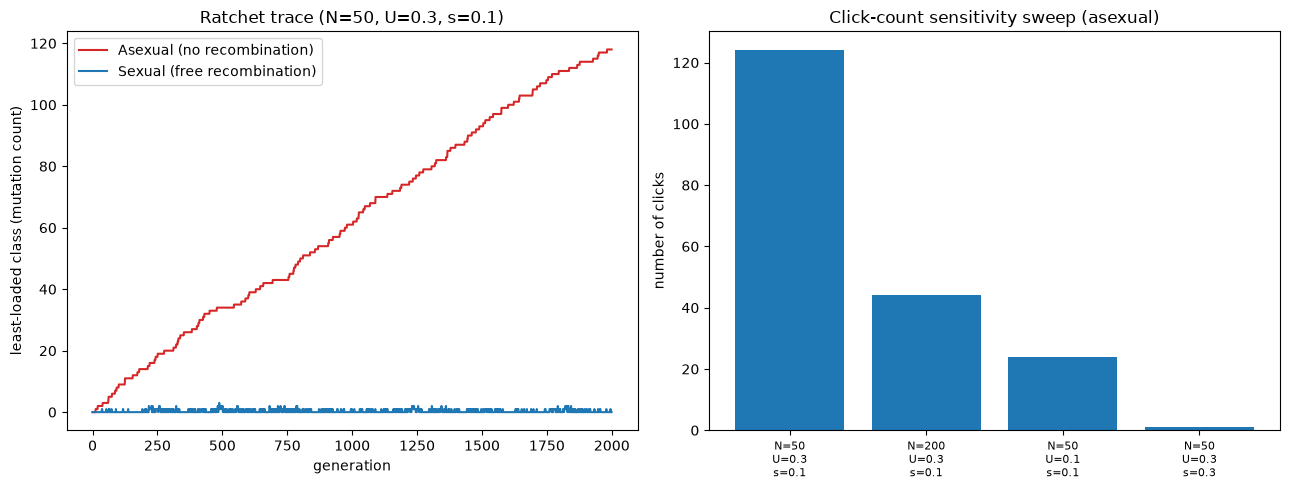

Exported results/hero_ratchet_rescue.png, results/sensitivity_sweep.csv,
results/rescue_comparison.csv, results/deterministic_equilibrium_check.txt


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(trace_asex, label="Asexual (no recombination)", color="tab:red", lw=1.5)
axes[0].plot(trace_sex, label="Sexual (free recombination)", color="tab:blue", lw=1.5)  # axes[0].plot(trace_sex, label="Sexual (free recombination)", color="tab:blue", lw=1.5)
axes[0].set_xlabel("generation")
axes[0].set_ylabel("least-loaded class (mutation count)")
axes[0].set_title(f"Ratchet trace (N={N_cmp}, U={U_cmp}, s={s_cmp})")
axes[0].legend()

axes[1].bar(range(len(sweep_df)), sweep_df["n_clicks"])  # axes[1].bar(range(len(sweep_df)), sweep_df["n_clicks"])
axes[1].set_xticks(range(len(sweep_df)))
axes[1].set_xticklabels([f"N={r.N}\nU={r.U}\ns={r.s}" for r in sweep_df.itertuples()], fontsize=8)
axes[1].set_ylabel("number of clicks")
axes[1].set_title("Click-count sensitivity sweep (asexual)")

plt.tight_layout()
plt.savefig("results/hero_ratchet_rescue.png", dpi=150)
plt.show()

sweep_df.to_csv("results/sensitivity_sweep.csv", index=False)
pd.DataFrame({
    "regime": ["low_U", "high_U"],
    "U": [U_cmp, U_high],
    "asexual_clicks": [len(clicks_asex), len(clicks_asex_high)],
    "sexual_clicks": [len(clicks_sex), len(clicks_sex_high)],
    "rescue_ratio": [rescue_ratio, rescue_ratio_high],
}).to_csv("results/rescue_comparison.csv", index=False)  # pd.DataFrame({...}).to_csv("results/rescue_comparison.csv", index=False)
with open("results/deterministic_equilibrium_check.txt", "w") as f:
    f.write(f"U={U}, s={s}\n")
    f.write(f"Deterministic equilibrium p[:10] = {p[:10]}\n")
    f.write(f"Closed-form Poisson(U/s) [:10]   = {theory}\n")
    f.write(f"max abs diff = {np.max(np.abs(p[:10]-theory))}\n")
    f.write(f"p0 = {p[0]}, exp(-U/s) = {np.exp(-U/s)}\n")
print("Exported results/hero_ratchet_rescue.png, results/sensitivity_sweep.csv,")
print("results/rescue_comparison.csv, results/deterministic_equilibrium_check.txt")
